In [5]:
# !pip install lightgbm scikit-learn pandas matplotlib   # uncomment if needed
%matplotlib inline
import importlib
import pandas as pd
import matplotlib.pyplot as plt
import src.higgs_lgbm as h
importlib.reload(h)   # picks up edits to the .py file without restarting the kernel

<module 'src.higgs_lgbm' from 'c:\\Users\\Emerson Carmine\\Documents\\School Projects\\higgs-boson-signal-classification\\src\\higgs_lgbm.py'>

In [6]:

# Full CERN Open Data v2 file (has KaggleSet / KaggleWeight columns)
train_df = pd.read_csv("data/atlas-higgs-challenge-2014-v2.csv")
print(train_df.shape)
print(train_df["Label"].value_counts())
print("Total weight by class:")
print(train_df.groupby("Label")["Weight"].sum())

(818238, 35)
Label
b    538678
s    279560
Name: count, dtype: int64
Total weight by class:
Label
b    410999.847322
s       691.988608
Name: Weight, dtype: float64


In [7]:
model, thr, val = h.train_lgbm(train_df)

Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.931812
[200]	valid_0's auc: 0.934635
[300]	valid_0's auc: 0.935397
[400]	valid_0's auc: 0.935762
[500]	valid_0's auc: 0.936009
[600]	valid_0's auc: 0.936147
[700]	valid_0's auc: 0.936224
[800]	valid_0's auc: 0.936331
[900]	valid_0's auc: 0.936363
[1000]	valid_0's auc: 0.936378
[1100]	valid_0's auc: 0.936399
[1200]	valid_0's auc: 0.93644
[1300]	valid_0's auc: 0.936454
[1400]	valid_0's auc: 0.936458
Early stopping, best iteration is:
[1389]	valid_0's auc: 0.936466
best iteration: 1389, threshold: 0.948, AMS: 3.820, events selected: 14.5%


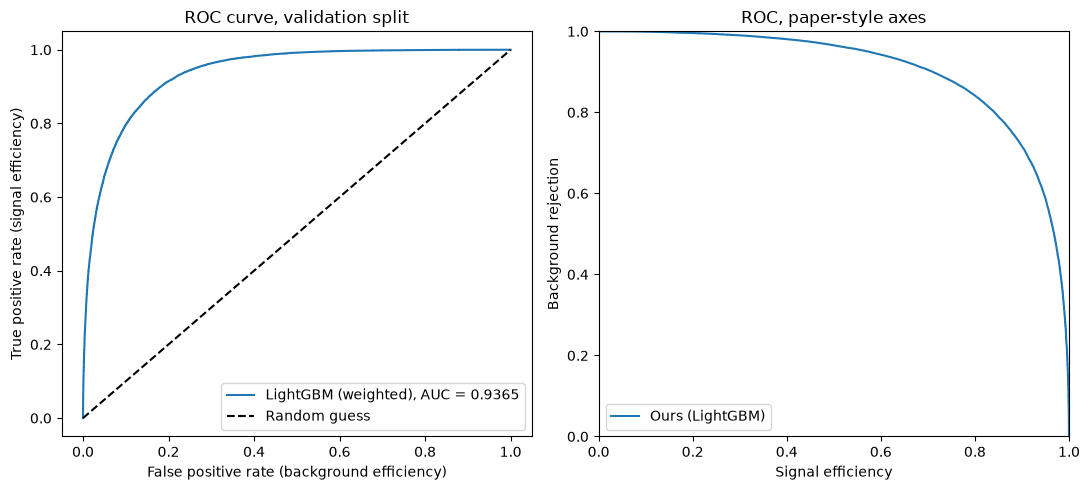

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
h.plot_roc(val, weighted=True, ax=axes[0])
h.plot_roc_paper_axes(val, weighted=False, ax=axes[1])
axes[1].set_title("ROC, paper-style axes")
plt.tight_layout()
plt.show()

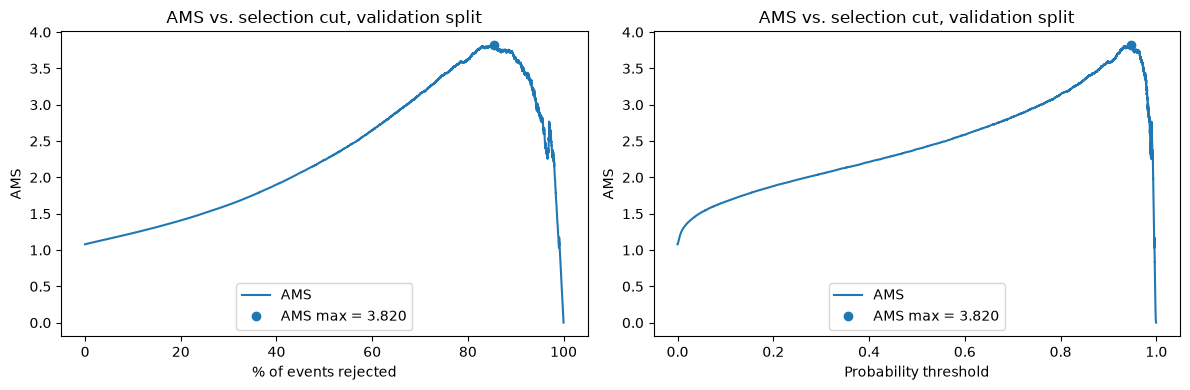

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
h.plot_ams_curve(val, x="rejected", ax=axes[0])    # like the paper's Fig. 10
h.plot_ams_curve(val, x="threshold", ax=axes[1])   # like the paper's Fig. 7b
plt.tight_layout()
plt.show()

Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.927559
[200]	valid_0's auc: 0.930532
[300]	valid_0's auc: 0.93138
[400]	valid_0's auc: 0.931781
[500]	valid_0's auc: 0.932048
[600]	valid_0's auc: 0.932256
[700]	valid_0's auc: 0.932367
[800]	valid_0's auc: 0.932448
[900]	valid_0's auc: 0.932513
[1000]	valid_0's auc: 0.932582
[1100]	valid_0's auc: 0.932613
[1200]	valid_0's auc: 0.93264
[1300]	valid_0's auc: 0.932643
Early stopping, best iteration is:
[1221]	valid_0's auc: 0.932654
best iteration: 1221, threshold: 0.945, AMS: 3.677, events selected: 14.2%
Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.879393
[200]	valid_0's auc: 0.88591
[300]	valid_0's auc: 0.894407
[400]	valid_0's auc: 0.899378
[500]	valid_0's auc: 0.9033
[600]	valid_0's auc: 0.906483
[700]	valid_0's auc: 0.907856
[800]	valid_0's auc: 0.909532
[900]	valid_0's auc: 0.910581
[1000]	valid_0's auc: 0.911516
[1100]	valid_0's auc: 0.912354
[1200]	valid_0

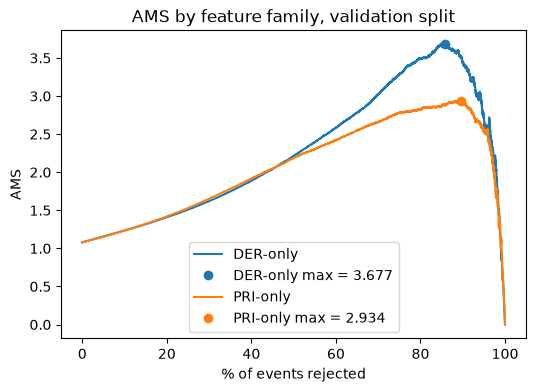

In [10]:
ams_by_group = {}
for feature_group in ("DER", "PRI"):
    _, _, ams_by_group[feature_group] = h.train_lgbm(train_df, feature_group=feature_group)

fig, ax = plt.subplots(figsize=(6, 4))
for feature_group, group_val in ams_by_group.items():
    h.plot_ams_curve(group_val, x="rejected", ax=ax, label=f"{feature_group}-only")
ax.set_title("AMS by feature family, validation split")
plt.show()